In [18]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans, AgglomerativeClustering

from scipy.cluster.hierarchy import dendrogram, linkage

print("Libraries imported successfully!")

Libraries imported successfully!


In [19]:
df = pd.read_csv("sales_data_sample.csv", encoding="latin1")

print("Dataset loaded successfully!")
print("Dataset shape:", df.shape)

df.head()

Dataset loaded successfully!
Dataset shape: (2823, 25)


,ORDERNUMBER,QUANTITYORDERED,PRICEEACH,ORDERLINENUMBER,SALES,ORDERDATE,STATUS,QTR_ID,MONTH_ID,YEAR_ID,...,ADDRESSLINE1,ADDRESSLINE2,CITY,STATE,POSTALCODE,COUNTRY,TERRITORY,CONTACTLASTNAME,CONTACTFIRSTNAME,DEALSIZE
0,10107,30,95.70,2,2871.00,2/24/2003 0:00,Shipped,1,2,2003,...,897 Long Airport Avenue,NaN,NYC,NY,10022,USA,NaN,Yu,Kwai,Small
1,10121,34,81.35,5,2765.90,5/7/2003 0:00,Shipped,2,5,2003,...,59 rue de l'Abbaye,NaN,Reims,NaN,51100,France,EMEA,Henriot,Paul,Small
2,10134,41,94.74,2,3884.34,7/1/2003 0:00,Shipped,3,7,2003,...,27 rue du Colonel Pierre Avia,NaN,Paris,NaN,75508,France,EMEA,Da Cunha,Daniel,Medium
3,10145,45,83.26,6,3746.70,8/25/2003 0:00,Shipped,3,8,2003,...,78934 Hillside Dr.,NaN,Pasadena,CA,90003,USA,NaN,Young,Julie,Medium
4,10159,49,100.00,14,5205.27,10/10/2003 0:00,Shipped,4,10,2003,...,7734 Strong St.,NaN,San Francisco,CA,NaN,USA,NaN,Brown,Julie,Medium


In [20]:
df.isnull().sum()

ORDERNUMBER            0
QUANTITYORDERED        0
PRICEEACH              0
ORDERLINENUMBER        0
SALES                  0
ORDERDATE              0
STATUS                 0
QTR_ID                 0
MONTH_ID               0
YEAR_ID                0
PRODUCTLINE            0
MSRP                   0
PRODUCTCODE            0
CUSTOMERNAME           0
PHONE                  0
ADDRESSLINE1           0
ADDRESSLINE2        2521
CITY                   0
STATE               1486
POSTALCODE            76
COUNTRY                0
TERRITORY           1074
CONTACTLASTNAME        0
CONTACTFIRSTNAME       0
DEALSIZE               0
dtype: int64

In [21]:
features = ['QUANTITYORDERED', 'PRICEEACH', 'SALES']

X = df[features].copy()


In [22]:
scaler = StandardScaler()

X_scaled = scaler.fit_transform(X)

In [23]:
wcss = []

for k in range(1, 11):
    kmeans = KMeans(n_clusters=k, random_state=42, n_init=10)
    kmeans.fit(X_scaled)

    wcss.append(kmeans.inertia_)

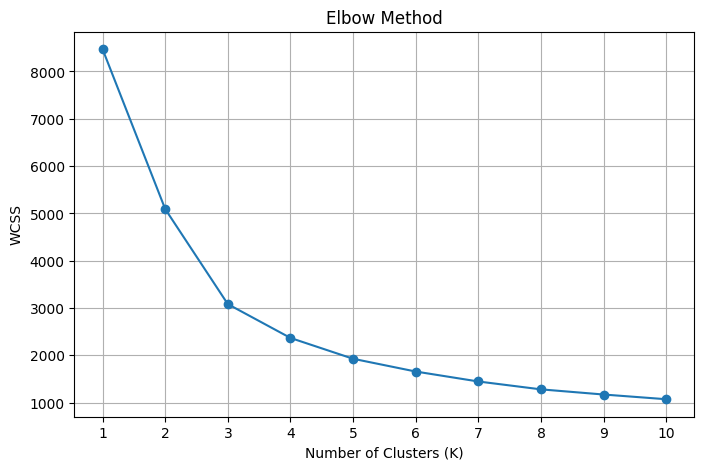

In [24]:
plt.figure(figsize=(8, 5))

plt.plot(range(1, 11), wcss, marker='o')

plt.title("Elbow Method")
plt.xlabel("Number of Clusters (K)")
plt.ylabel("WCSS")
plt.xticks(range(1, 11))
plt.grid(True)

plt.show()

In [25]:
optimal_k = 3

kmeans = KMeans(
    n_clusters=optimal_k,
    random_state=42
)

y_kmeans = kmeans.fit_predict(X_scaled)

In [31]:
df['KMeans_Cluster'] = y_kmeans

print("Cluster assignments:")
display(df[['QUANTITYORDERED', 'PRICEEACH', 'SALES',
            'KMeans_Cluster']].head(10))

Cluster assignments:


,QUANTITYORDERED,PRICEEACH,SALES,KMeans_Cluster
0,30,95.70,2871.00,2
1,34,81.35,2765.90,2
2,41,94.74,3884.34,1
3,45,83.26,3746.70,1
4,49,100.00,5205.27,1
5,36,96.66,3479.76,2
6,29,86.13,2497.77,2
7,48,100.00,5512.32,1
8,22,98.57,2168.54,2
9,41,100.00,4708.44,1


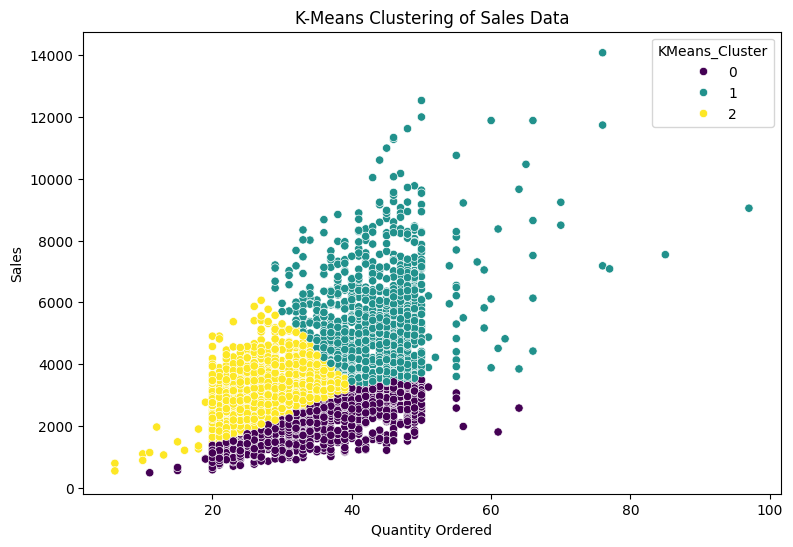

In [32]:
plt.figure(figsize=(9, 6))

sns.scatterplot(
    x='QUANTITYORDERED',
    y='SALES',
    hue='KMeans_Cluster',
    data=df,
    palette='viridis'
)

plt.title("K-Means Clustering of Sales Data")
plt.xlabel("Quantity Ordered")
plt.ylabel("Sales")
plt.show()

Text(0, 0.5, 'Euclidean Distance')

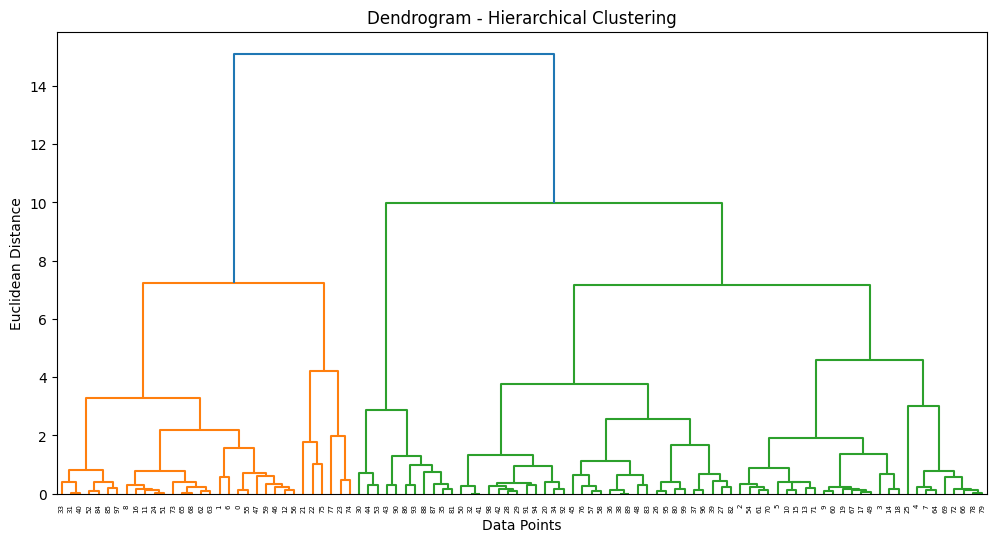

In [37]:
sample_data = X_scaled[:100]

# Perform hierarchical linkage
linked = linkage(sample_data, method='ward')

# Plot dendrogram
plt.figure(figsize=(12, 6))

dendrogram(linked)

plt.title("Dendrogram - Hierarchical Clustering")
plt.xlabel("Data Points")
plt.ylabel("Euclidean Distance")

In [38]:
hierarchical = AgglomerativeClustering(
    n_clusters=3,
    linkage='ward'
)

y_hierarchical = hierarchical.fit_predict(X_scaled)

print("Hierarchical clustering completed!")

Hierarchical clustering completed!


In [39]:
df['Hierarchical_Cluster'] = y_hierarchical

print("Hierarchical cluster assignments:")
display(
    df[['QUANTITYORDERED', 'PRICEEACH', 'SALES',
        'Hierarchical_Cluster']].head(10)
)

Hierarchical cluster assignments:


,QUANTITYORDERED,PRICEEACH,SALES,Hierarchical_Cluster
0,30,95.70,2871.00,2
1,34,81.35,2765.90,2
2,41,94.74,3884.34,1
3,45,83.26,3746.70,0
4,49,100.00,5205.27,1
5,36,96.66,3479.76,2
6,29,86.13,2497.77,2
7,48,100.00,5512.32,1
8,22,98.57,2168.54,2
9,41,100.00,4708.44,1


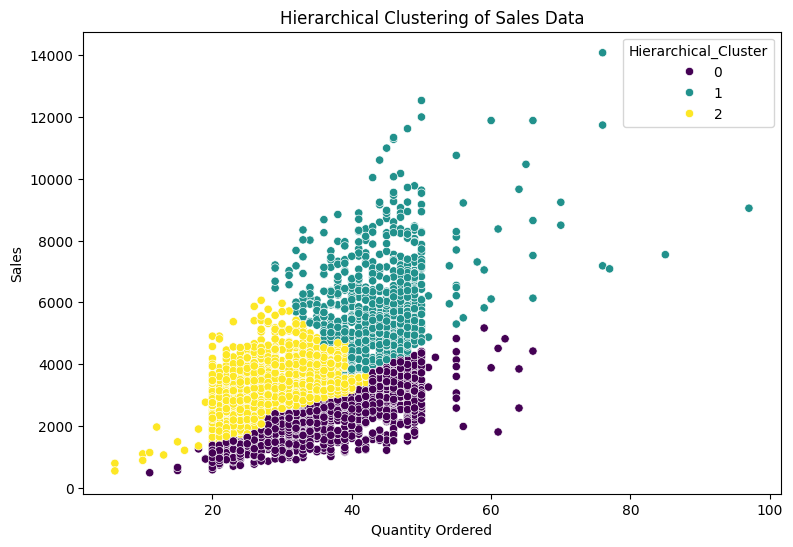

In [40]:
plt.figure(figsize=(9, 6))

sns.scatterplot(
    x='QUANTITYORDERED',
    y='SALES',
    hue='Hierarchical_Cluster',
    data=df,
    palette='viridis'
)

plt.title("Hierarchical Clustering of Sales Data")
plt.xlabel("Quantity Ordered")
plt.ylabel("Sales")

plt.show()